In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report


In [9]:
import tensorflow as ft
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical

In [10]:
df = sns.load_dataset("iris")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [13]:
X = df.drop(columns=["species"])

y=df["species"]

In [14]:
encoder=LabelEncoder()
y_int=encoder.fit_transform(y)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y_int, test_size=0.20, random_state=42,stratify=y_int) 

In [16]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

In [17]:
perceptron=Perceptron(max_iter=1000,random_state=42)
perceptron.fit(X_train_scaled,y_train)


,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [18]:
y_pred_percep=perceptron.predict(X_test_scaled)

In [19]:
accuracy_score(y_test,y_pred_percep)

0.9

In [20]:
print(classification_report(y_test,y_pred_percep))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.70      0.82        10
           2       0.77      1.00      0.87        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighted avg       0.92      0.90      0.90        30



In [ ]:
#now use model ANN

In [21]:
y_train_cat=to_categorical(y_train,num_classes=3)  #y_train and test has 3 calss so we make a seperate column for each class
y_test_cat=to_categorical(y_test,num_classes=3)

In [22]:
model=Sequential([
    Dense(16,input_dim=4,activation="relu"),
    Dense(8,activation="relu"),
    Dense(3,activation="softmax")
])

C:\Users\dell\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [24]:
history=model.fit(X_train_scaled,y_train_cat,
                  epochs=100,batch_size=8,validation_split=0.2,verbose=1)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.6146 - loss: 0.9880 - val_accuracy: 0.7500 - val_loss: 0.9650
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7708 - loss: 0.9210 - val_accuracy: 0.7917 - val_loss: 0.9042
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8125 - loss: 0.8606 - val_accuracy: 0.7917 - val_loss: 0.8487
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7917 - loss: 0.8057 - val_accuracy: 0.7500 - val_loss: 0.7984
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8021 - loss: 0.7560 - val_accuracy: 0.7500 - val_loss: 0.7544
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8125 - loss: 0.7107 - val_accuracy: 0.7500 - val_loss: 0.7155
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8646 - loss: 0.6668 - val_accuracy: 0.7500 - val_loss: 0.6816
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8542 - loss: 0.6274 - val_accuracy: 0.

In [25]:
loss,acc=model.evaluate(X_test_scaled,y_test_cat,verbose=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.9333 - loss: 0.1353


In [ ]:
#now i want to see how accuracy rise and val_accuracy

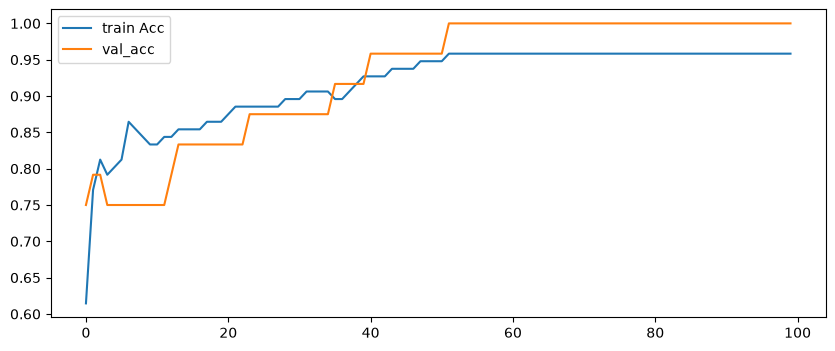

In [30]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["accuracy"], label="train Acc")
plt.plot(history.history["val_accuracy"], label="val_acc")
plt.legend()
